In [1]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import duecker_ET_model, simulate_dipole, jones_2009_model, MPIBackend
from hnn_core.cell import _get_gaussian_connection

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology

# import pandas as pd
from scipy import signal
from scipy.optimize import curve_fit
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
# plt.rcParams['svg.fonttype'] = 'none'
# plt.rcParams['pdf.fonttype'] = 'truetype'
mainpth = "/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/"
pathfig = os.path.join(mainpth, "new_model_HNN", "figures", "conn")
os.makedirs(pathfig, exist_ok=True)
pathpaper = os.path.join(mainpth, "methods_paper")

import sys

sys.path.append(os.path.join(mainpth, "utils"))
from general_plot_utils import assign_color, get_cmap_neurons

# colormap settings
from matplotlib import colormaps
import matplotlib.patches as mpatches

cmap = colormaps["Set2"]

cell_types = ["L2_inhibitory", "L2_pyramidal", "L5_inhibitory", "L5_pyramidal"]
cell_type_colors = {
    "L2_basket": cmap.colors[0],
    "L2_pyramidal": cmap.colors[1],
    "L5_basket": cmap.colors[3],
    "L5_pyramidal": cmap.colors[4],
}


# Hack a colormap

from scipy.interpolate import RectBivariateSpline
from hnn_core.extracellular import _get_laminar_z_coords, calculate_csd2d
from hnn_core.viz import plot_laminar_csd

# Literature insights

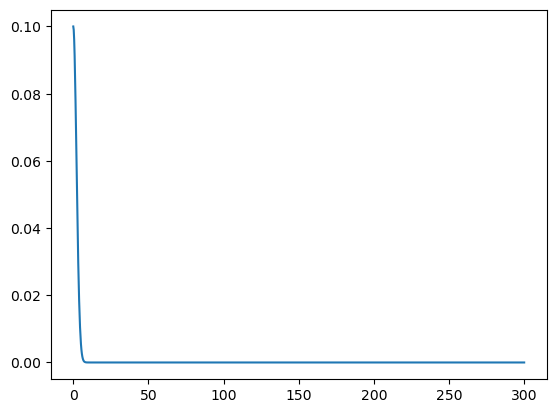

In [2]:
# Campagnola et al., 2022: Science, Fig. S5 suggests an all-to-all decay with gaussian = 130 um


def understand_space_constant(x, lamtha):
    """Explore effect of space constant on spike raster."""
    inplane_distance = 1  # example value
    A = 0.1
    return A * np.exp(-((x / (lamtha * inplane_distance)) ** 2))


x = np.linspace(0, 300, 1000)
plt.plot(x, understand_space_constant(x, 3))

In [3]:
# according to Campagnola et al., 2022, Science, SI, p. 10
def gauss(x, sigma):
    A = 0.1
    gau = A * np.exp(-(x**2) / (2.0 * sigma**2))

    return gau


p0 = [10]
y = understand_space_constant(x, 183.75)
params, cov = curve_fit(gauss, x, y, p0=p0)
params

array([129.93087104])

In [ ]:
inplane_distance = 30  # example value
lamtha = 183.75 / inplane_distance
lamtha

6.125

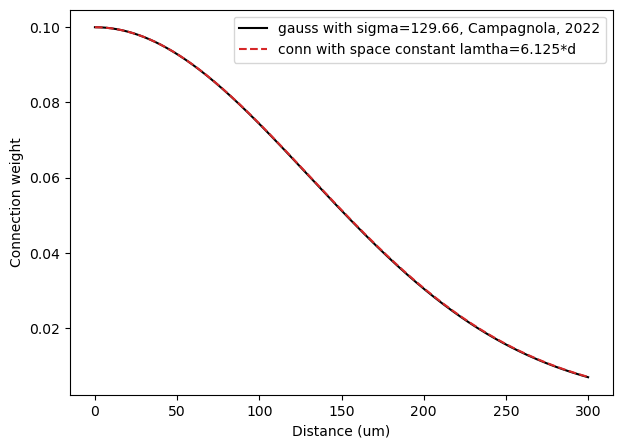

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    x,
    0.1 * np.exp(-(x**2) / (2 * 129.66**2)),
    label="gauss with sigma=129.66, Campagnola, 2022",
    color="k",
)
ax.plot(
    x, y, linestyle="--", label="conn with space constant lamtha=6.125*d", color="C3"
)
ax.set_xlabel("Distance (um)")
ax.set_ylabel("Connection weight")
ax.legend()
fig.savefig(f"{pathfig}/connection_space_constant.png")
fig.savefig(f"{pathfig}/connection_space_constant.pdf")

In [ ]:
# lamtha = 183.75 for inplane_distance = 30

# Rheobase

In [ ]:
## Not used in paper
def find_rheo(model="jones"):

    # fig, ax = plt.subplots(2,2, figsize=(12, 10))
    ax = ax.ravel()

    ampl = np.linspace(0.01, 1.0, 80)
    rheo = np.zeros((4,))

    for a in ampl:
        if model == "jones":
            net = jones_2009_model(mesh_shape=(1, 1))
        else:
            net = duecker_ET_model(mesh_shape=(1, 1))

        net.clear_connectivity()

        net.add_tonic_bias(cell_type="L2_basket", amplitude=a, t0=10.0, tstop=100.0)
        net.add_tonic_bias(cell_type="L5_basket", amplitude=a, t0=10.0, tstop=100.0)

        net.add_tonic_bias(cell_type="L2_pyramidal", amplitude=a, t0=10.0, tstop=100.0)
        net.add_tonic_bias(cell_type="L5_pyramidal", amplitude=a, t0=10.0, tstop=100.0)

        dpl = simulate_dipole(net, tstop=100, n_trials=1, dt=0.01, record_vsec="soma")

        for i in range(4):
            if i == 2:
                rheo[i] == rheo[0]
            if rheo[i] == 0:
                if any((np.array(net.cell_response.spike_gids[0]) == i)):
                    rheo[i] = a
                    ax[i].plot(
                        net.cell_response.times, net.cell_response.vsec[0][i]["soma"]
                    )
                    break

    return rheo


## Reported in paper
def find_basal_rheo(model="jones"):

    # fig, ax = plt.subplots(2,2, figsize=(12, 10))
    # ax = ax.ravel()

    ampl = np.linspace(0.01, 1.0, 80)
    rheo = np.zeros((4,))

    for a in ampl:
        if model == "jones":
            net = jones_2009_model(mesh_shape=(1, 1))
        else:
            net = duecker_ET_model(mesh_shape=(1, 1))

        net.clear_connectivity()

        net.add_tonic_bias(cell_type="L2_basket", amplitude=a, t0=10.0, tstop=100.0)
        net.add_tonic_bias(cell_type="L5_basket", amplitude=a, t0=10.0, tstop=100.0)

        net.add_tonic_bias(
            cell_type="L2_pyramidal",
            amplitude=a,
            t0=10.0,
            tstop=100.0,
            section="basal_2",
            bias_name="bias_1",
        )
        net.add_tonic_bias(
            cell_type="L2_pyramidal",
            amplitude=a,
            t0=10.0,
            tstop=100.0,
            section="basal_3",
            bias_name="bias_2",
        )
        net.add_tonic_bias(
            cell_type="L2_pyramidal",
            amplitude=a,
            t0=10.0,
            tstop=100.0,
            section="apical_oblique",
            bias_name="bias_3",
        )
        net.add_tonic_bias(
            cell_type="L5_pyramidal",
            amplitude=a,
            t0=10.0,
            tstop=100.0,
            section="basal_1",
            bias_name="bias_1",
        )
        net.add_tonic_bias(
            cell_type="L5_pyramidal",
            amplitude=a,
            t0=10.0,
            tstop=100.0,
            section="basal_2",
            bias_name="bias_2",
        )
        net.add_tonic_bias(
            cell_type="L5_pyramidal",
            amplitude=a,
            t0=10.0,
            tstop=100.0,
            section="apical_oblique",
            bias_name="apical_oblique",
        )

        dpl = simulate_dipole(net, tstop=100, n_trials=1, dt=0.01, record_vsec="soma")

        for i in range(4):
            if i == 2:
                rheo[i] == rheo[0]
            if rheo[i] == 0:
                if any((np.array(net.cell_response.spike_gids[0]) == i)):
                    rheo[i] = a
                    # ax[i].plot(net.cell_response.times, net.cell_response.vsec[0][i]['soma'])
                    break

    return rheo

In [ ]:
# find rheobases for Jones cells

rheo_jones = find_basal_rheo(model="jones")
# find rheobases for new cells
rheo_ca = find_basal_rheo(model="ca")

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction


/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:78: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applyi

KeyboardInterrupt: 

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction


<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:38: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:38: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_20482/2526185992.py:37: SyntaxWarning: invalid escape sequence '\m'
  ax[0,0].set_ylabel('membrane potential ($\mu$V)')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_20482/2526185992.py:38: SyntaxWarning: invalid escape sequence '\m'
  ax[1,0].set_ylabel('membrane potential ($\mu$V)')


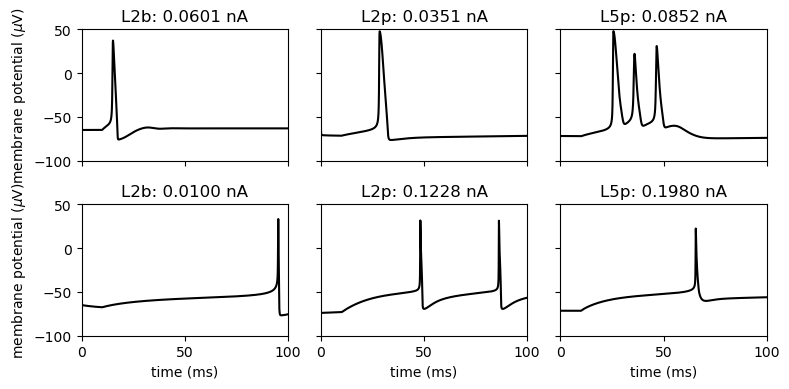

In [ ]:
## rheobase plots
cell_types = ["L2_basket", "L2_pyramidal", "L5_basket", "L5_pyramidal"]

jonnet = jones_2009_model(mesh_shape=(1, 1))
jonnet.clear_connectivity()

canet = duecker_ET_model(mesh_shape=(1, 1))
canet.clear_connectivity()

for i, c in enumerate(cell_types):
    if "basket" in c:
        jonnet.add_tonic_bias(
            cell_type=c, amplitude=rheo_jones[i], t0=10.0, tstop=100.0, section="soma"
        )
        canet.add_tonic_bias(
            cell_type=c, amplitude=rheo_ca[i], t0=10.0, tstop=100.0, section="soma"
        )
    else:
        jonnet.add_tonic_bias(
            cell_type=c,
            amplitude=rheo_jones[i],
            t0=10.0,
            tstop=100.0,
            section="basal_1",
            bias_name="bias_1",
        )
        canet.add_tonic_bias(
            cell_type=c,
            amplitude=rheo_ca[i],
            t0=10.0,
            tstop=100.0,
            section="basal_1",
            bias_name="bias_1",
        )
        jonnet.add_tonic_bias(
            cell_type=c,
            amplitude=rheo_jones[i],
            t0=10.0,
            tstop=100.0,
            section="basal_2",
            bias_name="bias_2",
        )
        canet.add_tonic_bias(
            cell_type=c,
            amplitude=rheo_ca[i],
            t0=10.0,
            tstop=100.0,
            section="basal_2",
            bias_name="bias_2",
        )
        jonnet.add_tonic_bias(
            cell_type=c,
            amplitude=rheo_jones[i],
            t0=10.0,
            tstop=100.0,
            section="apical_oblique",
            bias_name="apical_oblique",
        )
        canet.add_tonic_bias(
            cell_type=c,
            amplitude=rheo_ca[i],
            t0=10.0,
            tstop=100.0,
            section="apical_oblique",
            bias_name="apical_oblique",
        )
# simulate dipole
dpl_jon = simulate_dipole(jonnet, tstop=100, n_trials=1, record_vsec="soma")
dpl_ca = simulate_dipole(canet, tstop=100, n_trials=1, record_vsec="soma")
fig, ax = plt.subplots(2, 3, figsize=(8, 4), sharex=True, sharey=True)

cell_types = ["L2b", "L2p", "L5b", "L5p"]
for i in range(3):
    if i == 2:
        c = i + 1
    else:
        c = i
    ax[0, i].plot(
        jonnet.cell_response.times, jonnet.cell_response.vsec[0][c]["soma"], color="k"
    )
    ax[1, i].plot(
        jonnet.cell_response.times, canet.cell_response.vsec[0][c]["soma"], color="k"
    )
    ax[0, i].set_title(f"{cell_types[c]}: {rheo_jones[c]:.4f} nA")
    ax[1, i].set_title(f"{cell_types[c]}: {rheo_ca[c]:.4f} nA")
    ax[1, i].set_xlabel("time (ms)")
    ax[0, 0].set_ylabel("membrane potential ($\mu$V)")
    ax[1, 0].set_ylabel("membrane potential ($\mu$V)")
    ax[0, i].set_ylim(-100, 50)
    ax[1, i].set_ylim(-100, 50)
    ax[0, i].set_xlim(0, 100)
    ax[0, i].set_xticks([0, 50, 100])

fig.tight_layout()
fig.savefig(pathfig + "rheobase_comparison.png")

## Jones model behavior

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction


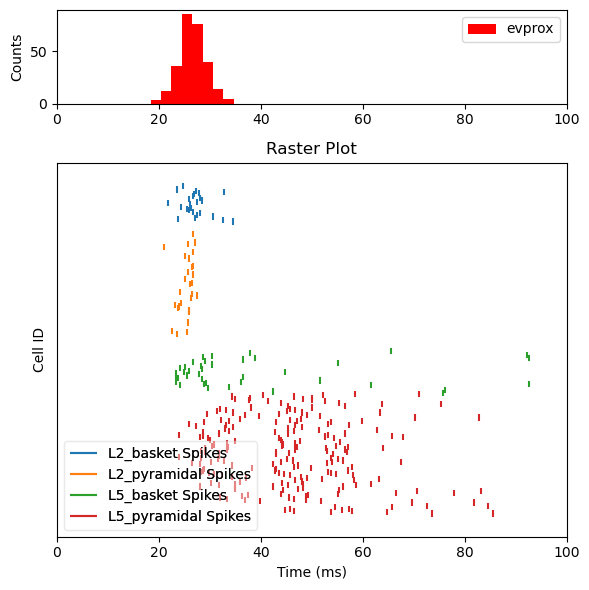

In [ ]:
net = jones_2009_model()

weights_ampa_p1 = {
    "L2_basket": 1,
    "L2_pyramidal": 1.0,
    "L5_basket": 1,
    "L5_pyramidal": 1.0,
}
weights_nmda_p1 = {
    "L2_basket": 1,
    "L2_pyramidal": 1.0,
    "L5_basket": 1,
    "L5_pyramidal": 1.0,
}
synaptic_delays_prox = {
    "L2_basket": 0.1,
    "L2_pyramidal": 0.1,
    "L5_basket": 1.0,
    "L5_pyramidal": 1.0,
}


# all NMDA weights are zero; pass None explicitly
net.add_evoked_drive(
    "evprox",
    mu=26.61,
    sigma=2.47,
    numspikes=1,
    weights_ampa=weights_ampa_p1,
    weights_nmda=None,
    location="proximal",
    synaptic_delays=synaptic_delays_prox,
    event_seed=544,
)

dpl = simulate_dipole(
    net, tstop=100, n_trials=1, record_vsec="all", record_isec="all", record_ca="all"
)


fig, ax = plt.subplots(2, 1, figsize=(6, 6), height_ratios=[0.25, 1])

net.cell_response.plot_spikes_hist(ax=ax[0], spike_types=["evprox"], show=False)
net.cell_response.plot_spikes_raster(ax=ax[1], show=False)

fig.tight_layout()
fig.savefig(os.path.join(pathfig, "jones_spikes_prox.png"))

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applyi

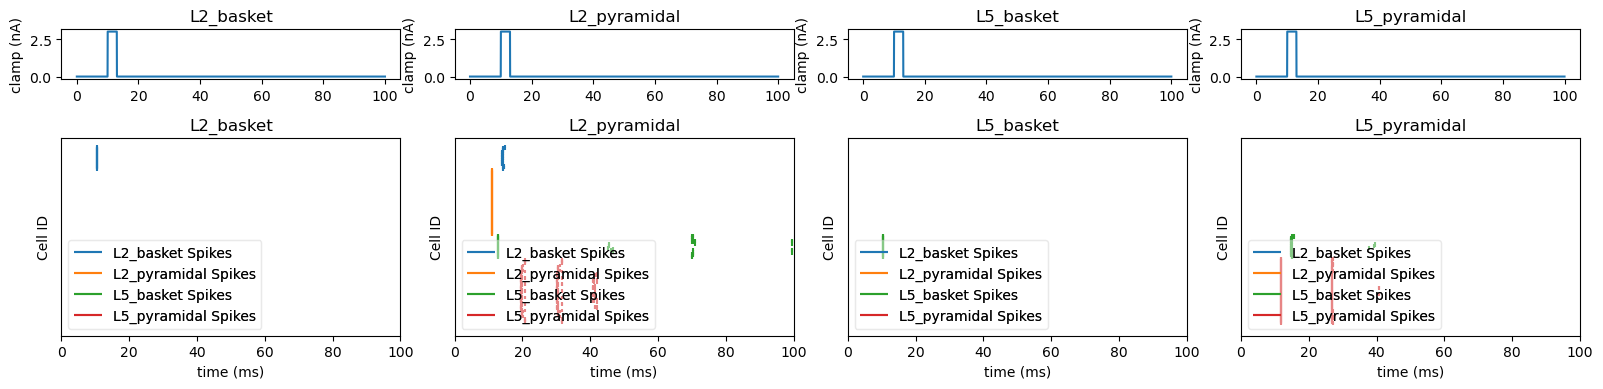

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(16, 4), height_ratios=[0.25, 1])
cell_types = ["L2_basket", "L2_pyramidal", "L5_basket", "L5_pyramidal"]

for i, c in enumerate(cell_types):
    # stimulate L2/3 pyramidal
    net = jones_2009_model()

    net.set_cell_positions(inplane_distance=30.0)

    depths = list(list(range(-100, 2200, 200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array("probe1", electrode_pos)

    ampl = 3.0
    t0 = 10

    net.add_tonic_bias(
        cell_type=c,
        section="soma",
        bias_name="tonic_soma",
        amplitude=ampl,
        t0=t0,
        tstop=t0 + 3,
    )

    dpl = simulate_dipole(
        net,
        tstop=100,
        n_trials=1,
        record_vsec="all",
        record_isec="all",
        record_ca="all",
    )

    # clamp signal for plotting
    timevec = net.cell_response.times

    clamp = np.zeros_like(timevec)

    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]["t0"]))
            tstop = np.argmin(
                np.abs(timevec - net.external_biases[bias][cell_type]["tstop"])
            )

            clamp[t0:tstop] = net.external_biases[bias][cell_type]["amplitude"]

    ax[0, i].plot(timevec, clamp)
    ax[0, i].set_ylabel("clamp (nA)")
    ax[0, i].set_title(f"{cell_types[i]}")
    net.cell_response.plot_spikes_raster(ax=ax[1, i], show=False)
    ax[1, i].set_title(f"{cell_types[i]}")
    ax[1, i].set_xlabel("time (ms)")

    del net

for i in range(3):
    ax[1, i].set_ylim([ax[1, 3].get_ylim()[0], ax[1, 3].get_ylim()[1]])
fig.tight_layout()
fig.savefig(os.path.join(pathfig, "jones_inter_layer.png"))

# the effect of L2/3 pyramidal stimulation on the L5 pyramidal cell is quite late (but removing connection gets rid of it so that's what's driving it)

# Connectivity

<>:53: SyntaxWarning: invalid escape sequence '\m'
<>:53: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_39195/2943158151.py:53: SyntaxWarning: invalid escape sequence '\m'
  cb.set_label('synaptic weight ($\mu S$)')


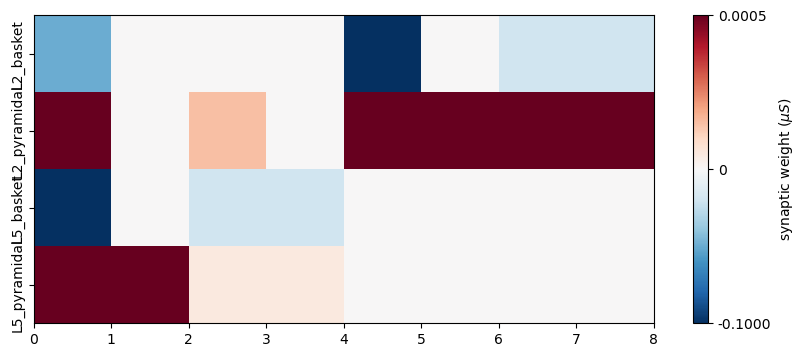

In [ ]:
net = duecker_ET_model()

sources = [
    "L5_pyramidal",
    "L5_basket",
    "L2_pyramidal",
    "L2_basket",
]
E_receptors = ["ampa", "nmda"]
I_receptors = ["gabaa", "gabab"]

connectivity_data = dict()

for source in sources:
    connectivity_data[source] = dict()
    for conn in net.connectivity:
        if conn["src_type"] == source:
            t_type = conn["target_type"]
            check_t = connectivity_data[source].get(t_type)

            if check_t is None:
                connectivity_data[source][t_type] = dict()
            rec = conn["receptor"]
            connectivity_data[source][t_type][rec] = conn["nc_dict"]["A_weight"]


conn_im = np.zeros((len(sources), len(sources), 2))

xticklabels = dict()
for s, source in enumerate(sources):
    xticks_source = []
    for t, target in enumerate(sources):
        check_t = connectivity_data[source].get(target)
        if "basket" in source and check_t is not None:
            for i, rec in enumerate(I_receptors):
                if rec in connectivity_data[source][target]:
                    conn_im[s, t, i] = -connectivity_data[source][target][rec]
                xticks_source.append(f"{target}_{rec}")
        elif "pyramidal" in source and check_t is not None:
            for i, rec in enumerate(E_receptors):
                if rec in connectivity_data[source][target]:
                    conn_im[s, t, i] = connectivity_data[source][target][rec]
                xticks_source.append(f"{target}_{rec}")
    xticklabels[source] = xticks_source

from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(10, 4))
norm = TwoSlopeNorm(
    vmin=np.min(conn_im + 0.1), vmax=np.round(np.max(conn_im), 4), vcenter=0
)
im = ax.pcolormesh(
    conn_im.reshape(len(sources), len(sources) * 2), cmap="RdBu_r", norm=norm
)
ax.set_yticks(np.arange(0.5, 4.5, 1))
ax.set_yticklabels(sources, rotation="vertical", va="center")
ax.set_xticks(np.arange(0.5, 8.5, 1))
ax.set_xticklabels(xticklabels["L2_pyramidal"], rotation=45)
cb = plt.colorbar(im)
cb.set_ticks([np.min(conn_im + 0.1), 0, np.round(np.max(conn_im), 4)])
cb.set_ticklabels(
    [f"{np.min(conn_im + 0.1):.4f}", "0", f"{np.round(np.max(conn_im), 4):.4f}"]
)
cb.set_label("synaptic weight ($\mu S$)")

# fig.savefig(os.path.join(pathfig, 'conn_matrix.png'))
# fig.savefig(os.path.join(pathfig, 'conn_matrix.pdf'))
# fig.savefig(os.path.join(pathfig, 'conn_matrix.svg'))

In [ ]:
xticklabels

{'L5_pyramidal': ['L5_pyramidal_ampa',
  'L5_pyramidal_nmda',
  'L5_basket_ampa',
  'L5_basket_nmda'],
 'L5_basket': ['L5_pyramidal_gabaa',
  'L5_pyramidal_gabab',
  'L5_basket_gabaa',
  'L5_basket_gabab'],
 'L2_pyramidal': ['L5_pyramidal_ampa',
  'L5_pyramidal_nmda',
  'L5_basket_ampa',
  'L5_basket_nmda',
  'L2_pyramidal_ampa',
  'L2_pyramidal_nmda',
  'L2_basket_ampa',
  'L2_basket_nmda'],
 'L2_basket': ['L5_pyramidal_gabaa',
  'L5_pyramidal_gabab',
  'L2_pyramidal_gabaa',
  'L2_pyramidal_gabab',
  'L2_basket_gabaa',
  'L2_basket_gabab']}

# Strong proximal

In [ ]:
net = duecker_ET_model()
weights_ampa_p1 = {
    "L2_basket": 0.0,
    "L2_pyramidal": 1.0,
    "L5_basket": 0.0,
    "L5_pyramidal": 1.0,
}
weights_nmda_p1 = {
    "L2_basket": 0.0,
    "L2_pyramidal": 1.0,
    "L5_basket": 0.0,
    "L5_pyramidal": 1.0,
}
synaptic_delays_prox = {
    "L2_basket": 0.1,
    "L2_pyramidal": 0.1,
    "L5_basket": 0.1,
    "L5_pyramidal": 0.1,
}


net.add_evoked_drive(
    "evprox",
    mu=26.61,
    sigma=6,
    numspikes=1,
    weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1,
    location="proximal",
    synaptic_delays=synaptic_delays_prox,
)

with MPIBackend(n_procs=10, mpi_cmd="mpiexec"):
    dpl = simulate_dipole(net, tstop=400, n_trials=1, bsl_cor="duecker")


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

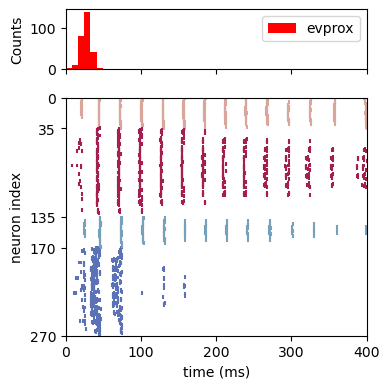

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(4, 4), height_ratios=[0.25, 1], sharex=True)

net.cell_response.plot_spikes_hist(ax=ax[0], spike_types=["evprox"], show=False)

# spiking
I = np.array(net.cell_response.spike_gids[0]) < 270
gids = np.array(net.cell_response.spike_gids).reshape(
    -1,
)[I]
times = np.array(net.cell_response.spike_times).reshape(
    -1,
)[I]
cell_types = ["L2_inhibitory", "L2_pyramidal", "L5_inhibitory", "L5_pyramidal"]
cell_type_colors = {
    "L2_basket": cmap.colors[0],
    "L2_pyramidal": cmap.colors[1],
    "L5_basket": cmap.colors[2],
    "L5_pyramidal": cmap.colors[3],
}

colors = [assign_color(net, gid) for gid in gids]

ax[1].scatter(times, gids, s=8, alpha=1.0, c=colors, marker="|")
ax[1].set_ylabel("neuron index")
# ax[1].set_xlim([0, 175])
# ax[1].set_xticks(np.arange(0, 176, 25))

ax[1].set_xlabel("time (ms)")
ax[1].set_ylim([0, 270])
ax[1].set_yticks([0, 35, 135, 170, 270])
ax[1].invert_yaxis()
# ax2 = ax[1].twinx()
# ax2.plot(dpl[0].times, dpl[0].data['agg'], color='k')
fig.tight_layout()

fig.savefig(os.path.join(pathfig, "net_rsp_prox_new_NMDA_new_lamtha.png"))

In [ ]:
net = duecker_ET_model()

# this is from the plotting function
exc_cells = ["L2_pyramidal", "L5_pyramidal"]
inh_cells = ["L2_basket", "L5_basket"]

pos_l5 = np.zeros((100, 3))
for p, pos in enumerate(net.pos_dict["L5_pyramidal"]):
    pos_l5[p] = np.array(pos)

l5_gid = 170
pos_dict_idx = int(l5_gid) - 170
ref_pos = net.pos_dict["L5_pyramidal"][pos_dict_idx]
conn = net.connectivity[2]
l5_center_conn_bl = np.zeros((10, 10))
for pos in net.pos_dict["L5_pyramidal"]:
    target_pos = pos
    weight, _ = _get_gaussian_connection(
        ref_pos, target_pos, conn["nc_dict"], inplane_distance=net._inplane_distance
    )

    x_idx = int(target_pos[0])
    y_idx = int(target_pos[1])
    l5_center_conn_bl[x_idx, y_idx] = weight

ref_pos = (4, 4, 0)
l5_center_conn_c = np.zeros((10, 10))
for pos in net.pos_dict["L5_pyramidal"]:
    target_pos = pos
    weight, _ = _get_gaussian_connection(
        ref_pos, target_pos, conn["nc_dict"], inplane_distance=net._inplane_distance
    )

    x_idx = int(target_pos[0])
    y_idx = int(target_pos[1])
    l5_center_conn_c[x_idx, y_idx] = weight

l5_gid = 269
pos_dict_idx = int(l5_gid) - 170
ref_pos = net.pos_dict["L5_pyramidal"][pos_dict_idx]
conn = net.connectivity[2]
l5_center_conn_tr = np.zeros((10, 10))
for pos in net.pos_dict["L5_pyramidal"]:
    target_pos = pos
    weight, _ = _get_gaussian_connection(
        ref_pos, target_pos, conn["nc_dict"], inplane_distance=net._inplane_distance
    )

    x_idx = int(target_pos[0])
    y_idx = int(target_pos[1])
    l5_center_conn_tr[x_idx, y_idx] = weight


In [ ]:
## Inhibitory
pos_l5 = np.zeros((100, 3))
for p, pos in enumerate(net.pos_dict["L5_basket"]):
    pos_l5[p] = np.array(pos)

inh_gid = 135
pos_dict_idx = int(inh_gid) - 135
ref_pos = net.pos_dict["L5_basket"][pos_dict_idx]
conn = net.connectivity[2]
inh_center_conn_bl = np.zeros((10, 10))
for pos in net.pos_dict["L5_basket"]:
    target_pos = pos
    weight, _ = _get_gaussian_connection(
        ref_pos, target_pos, conn["nc_dict"], inplane_distance=net._inplane_distance
    )

    x_idx = int(target_pos[0])
    y_idx = int(target_pos[1])
    inh_center_conn_bl[x_idx, y_idx] = weight

inh_gid = 150
pos_dict_idx = int(inh_gid) - 135
ref_pos = net.pos_dict["L5_basket"][pos_dict_idx]
inh_center_conn_c = np.zeros((10, 10))
for pos in net.pos_dict["L5_basket"]:
    target_pos = pos
    weight, _ = _get_gaussian_connection(
        ref_pos, target_pos, conn["nc_dict"], inplane_distance=net._inplane_distance
    )

    x_idx = int(target_pos[0])
    y_idx = int(target_pos[1])
    inh_center_conn_c[x_idx, y_idx] = weight

inh_gid = 169
pos_dict_idx = int(inh_gid) - 135
ref_pos = net.pos_dict["L5_basket"][pos_dict_idx]
conn = net.connectivity[2]
inh_center_conn_tr = np.zeros((10, 10))
for pos in net.pos_dict["L5_basket"]:
    target_pos = pos
    weight, _ = _get_gaussian_connection(
        ref_pos, target_pos, conn["nc_dict"], inplane_distance=net._inplane_distance
    )

    x_idx = int(target_pos[0])
    y_idx = int(target_pos[1])
    inh_center_conn_tr[x_idx, y_idx] = weight

In [ ]:
cb.set_ticks

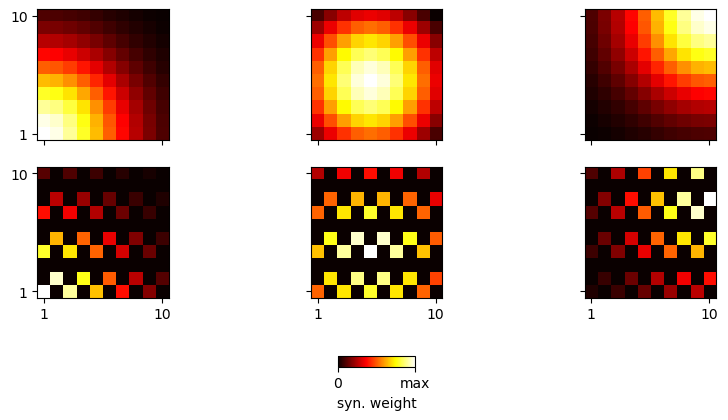

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(10, 5), sharex=True, sharey=True)
ax[0, 0].imshow(l5_center_conn_bl, origin="lower", cmap="hot")
ax[0, 1].imshow(l5_center_conn_c, origin="lower", cmap="hot")
ax[0, 2].imshow(l5_center_conn_tr, origin="lower", cmap="hot")

ax[1, 0].imshow(inh_center_conn_bl, origin="lower", cmap="hot")
ax[1, 1].imshow(inh_center_conn_c, origin="lower", cmap="hot")
im = ax[1, 2].imshow(inh_center_conn_tr, origin="lower", cmap="hot")
cb = fig.colorbar(
    im,
    ax=ax,
    shrink=0.1,
    fraction=0.1,
    aspect=7,
    label="syn. weight",
    orientation="horizontal",
)
cb.set_ticks([0, 0.00025])
cb.set_ticklabels([f"0", "max"])
ax[0, 0].set_xlim([-0.5, 9.5])
ax[0, 0].set_ylim([-0.5, 9.5])
ax[0, 0].set_xticks([0, 9])
ax[0, 0].set_yticks([0, 9])
ax[0, 0].set_xticklabels([1, 10])
ax[0, 0].set_yticklabels([1, 10])

fig.savefig(os.path.join(pathfig, "single_neuro_conn.png"))
fig.savefig(os.path.join(pathfig, "single_neuro_conn.pdf"))

In [ ]:
import hnn_core
import os.path as op
from hnn_core import read_params

hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, "param", "default_human_ET.json")
params = read_params(params_fname)

In [ ]:
net = duecker_ET_model()
ampl = 1
t0 = 10

net.add_tonic_bias(
    cell_type="L2_pyramidal",
    section="soma",
    bias_name="tonic_soma",
    amplitude=ampl,
    t0=t0,
    tstop=t0 + 10,
)

# with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
dpl = simulate_dipole(net, tstop=200, n_trials=1, record_isec="all")

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Applying Jones baseline correction


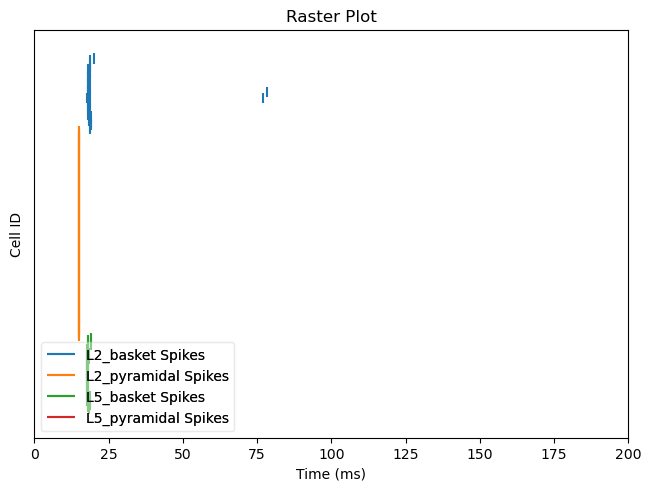

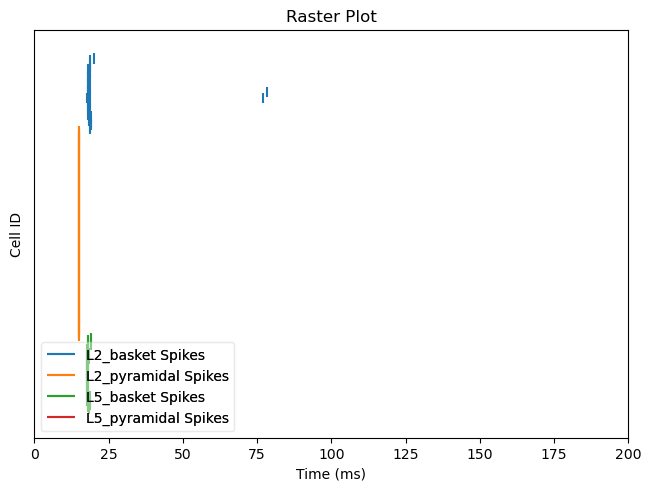

In [ ]:
net.cell_response.plot_spikes_raster()

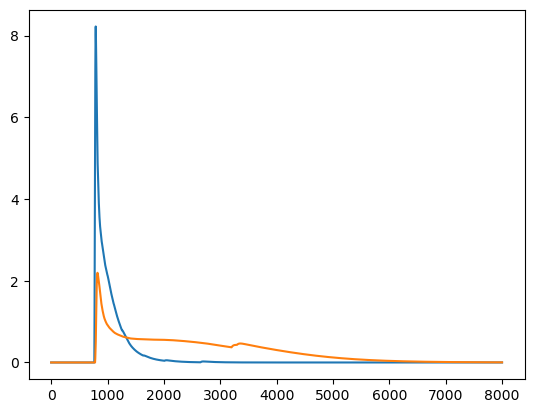

In [ ]:
plt.plot(net.cell_response.isec[0][170]["soma"]["soma_gabaa"])
plt.plot(net.cell_response.isec[0][170]["apical_2"]["apical_2_gabaa"])

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/parallel_backends.py:481: UserWarning: Failed to kill nrniv process(es) 15610,15606,15613,15608,15614,15609,15615,15611,15607
  warn("Failed to kill nrniv process(es) %s" % ",".join(pids))


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from 

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/parallel_backends.py:481: UserWarning: Failed to kill nrniv process(es) 15610,15606,15613,15608,15614,15609,15615,15611,15607
  warn("Failed to kill nrniv process(es) %s" % ",".join(pids))


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/parallel_backends.py:481: UserWarning: Failed to kill nrniv process(es) 15610,15606,15613,15608,15614,15609,15615,15611,15607
  warn("Failed to kill nrniv process(es) %s" % ",".join(pids))


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/parallel_backends.py:481: UserWarning: Failed to kill nrniv process(es) 15610,15606,15613,15608,15614,15609,15615,15611,15607
  warn("Failed to kill nrniv process(es) %s" % ",".join(pids))


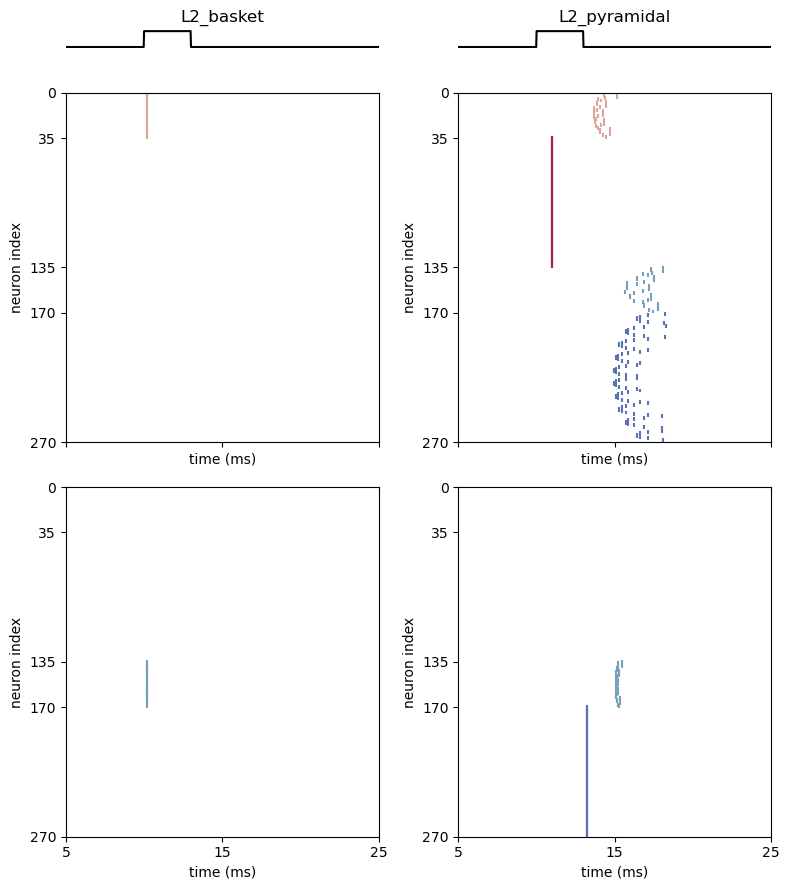

In [ ]:
fig, ax = plt.subplots(3, 2, figsize=(8, 9), height_ratios=[0.05, 1, 1], sharex=True)

ax = ax.flatten()
cell_types = ["L2_basket", "L2_pyramidal", "L5_basket", "L5ET"]
for i, c in enumerate(cell_types):
    # stimulate L2/3 pyramidal
    net = duecker_ET_model()
    ampl = 3.0
    t0 = 10

    net.add_tonic_bias(
        cell_type=c,
        section="soma",
        bias_name="tonic_soma",
        amplitude=ampl,
        t0=t0,
        tstop=t0 + 3,
    )

    with MPIBackend(n_procs=10, mpi_cmd="mpiexec"):
        dpl = simulate_dipole(net, tstop=30, n_trials=1)

    # clamp signal for plotting
    timevec = net.cell_response.times

    clamp = np.zeros_like(timevec)

    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]["t0"]))
            tstop = np.argmin(
                np.abs(timevec - net.external_biases[bias][cell_type]["tstop"])
            )

            clamp[t0:tstop] = net.external_biases[bias][cell_type]["amplitude"]

    if i < 2:
        ax[i].plot(timevec, clamp, color="k", linewidth=1.5)
        ax[i].set_ylabel("clamp (nA)")
        ax[i].set_title(f"{cell_types[i]}")
        ax[i].set_xlim([5, 25])
        ax[i].set_axis_off()

    I = np.array(net.cell_response.spike_gids[0]) < 270
    gids = np.array(net.cell_response.spike_gids).reshape(
        -1,
    )[I]
    times = np.array(net.cell_response.spike_times).reshape(
        -1,
    )[I]
    cell_types = ["L2_inhibitory", "L2_pyramidal", "L5_inhibitory", "L5ET"]
    cell_type_colors = {
        "L2_basket": cmap.colors[0],
        "L2_pyramidal": cmap.colors[1],
        "L5_basket": cmap.colors[2],
        "L5ET": cmap.colors[3],
    }

    colors = [assign_color(net, gid) for gid in gids]

    ax[i + 2].scatter(times, gids, s=8, alpha=1.0, c=colors, marker="|")
    ax[i + 2].set_ylabel("neuron index")
    ax[i + 2].set_xlim([5, 25])
    ax[i + 2].set_xticks(np.arange(5, 26, 10))
    ax[i + 2].set_xlabel("time (ms)")
    ax[i + 2].set_ylim([0, 270])
    ax[i + 2].set_yticks([0, 35, 135, 170, 270])
    ax[i + 2].invert_yaxis()

for i in range(3):
    ax[i + 2].set_ylim([ax[i + 2].get_ylim()[0], ax[i + 2].get_ylim()[1]])
fig.tight_layout()
fig.savefig(os.path.join(pathfig, "new_model_inter_layer_exp.png"))
fig.savefig(os.path.join(pathfig, "new_model_inter_layer_exp.pdf"))

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:86: UserWarning: No external drives or biases loaded
  warnings.warn("No external drives or biases loaded", UserWarning)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying calcium model baseline correction


In [2]:

net_no_stim = duecker_ET_model()
dpl = simulate_dipole(
    net_no_stim, tstop=40, dt=0.05, bsl_cor="duecker", record_vsec="soma"
)

def get_psp(src_cell, trgt_cell, ampl,tsamp,):

    net = duecker_ET_model()
    g = net_no_stim.gid_ranges[src_cell][int(len(net_no_stim.gid_ranges[src_cell])/2)]
    psp_gid = np.setdiff1d(net.gid_ranges[trgt_cell], g)

    num_sweeps = len(net.gid_ranges[trgt_cell])
    if src_cell == trgt_cell:
        num_sweeps -=1
    psp = np.zeros((num_sweeps,1))
    v_mem = np.zeros((num_sweeps, tsamp))

    net.add_tonic_bias(cell_type=src_cell, gid=g, bias_name="tonic_soma", amplitude=ampl, t0=10, tstop=15)

    dpl = simulate_dipole(net, tstop=40, dt=0.05, bsl_cor="duecker", record_vsec="soma")

    for ei, e in enumerate(psp_gid):
        v = np.array(net.cell_response.vsec[0][e]["soma"])
        bsl = np.array(net_no_stim.cell_response.vsec[0][e]["soma"])
        psp[ei] = np.max(np.abs(v - bsl))
        v_mem[ei] = v

    return psp, v_mem



KeyError: 'L5ET_pyramidal_basal_gbar_NaTs2_t'

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying calcium model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying calcium model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying calcium model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Applying calcium model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
B

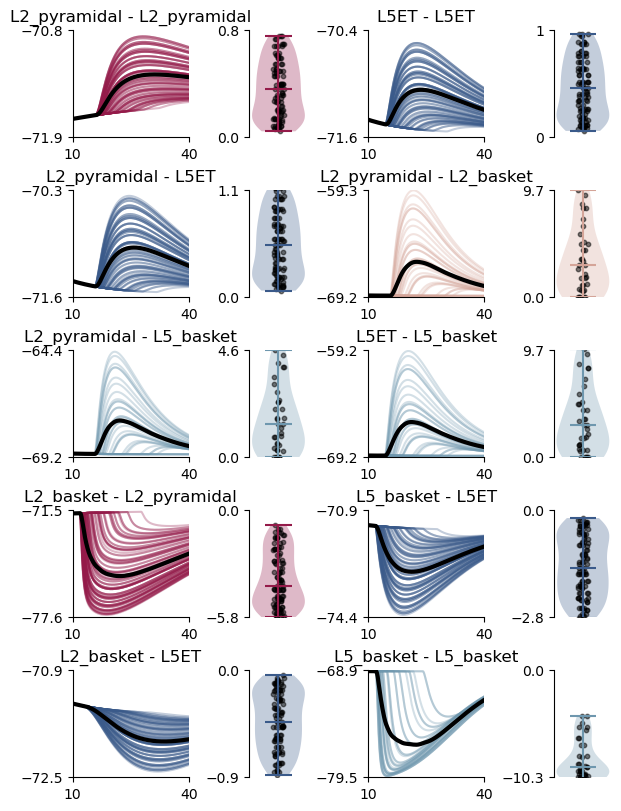

In [ ]:
fig, ax = plt.subplots(5, 4,figsize=(6, 8), constrained_layout=True, width_ratios=[1, 0.5, 1, 0.5])
ax = ax.flatten()
src_cells = ["L2_pyramidal", "L5ET", "L2_pyramidal", "L2_pyramidal", "L2_pyramidal", "L5ET", "L2_basket", "L5_basket", "L2_basket", "L5_basket"]
trgt_cells = ["L2_pyramidal", "L5ET", "L5ET", "L2_basket", "L5_basket", "L5_basket", "L2_pyramidal", "L5ET", "L5ET", "L5_basket"]
neuron_cols = {"L2_basket": '#d4a498',
               "L2_pyramidal": '#941a49',
               "L5_basket": '#6e97ae',
               "L5ET": '#3a5a8a'}

aidx = 0
for src, trgt in zip(src_cells, trgt_cells):

    if src == "L5ET":
        ampl = 3
    elif src == "L2_pyramidal":
        ampl = 1
    elif src == "L2_basket":
        ampl = 0.5

    psp, vmem = get_psp(src_cell=src, trgt_cell=trgt, ampl=ampl, tsamp=len(dpl[0].times))
    ax[aidx].plot(dpl[0].times, vmem.T, color=neuron_cols[trgt], alpha=0.3)
    ax[aidx].plot(dpl[0].times, vmem.mean(axis=0), color='k', linewidth=3)
    ax[aidx].spines['top'].set_visible(False)
    ax[aidx].spines['right'].set_visible(False)
    ax[aidx].set_xlim(left=10)
    ax[aidx].set_title('')
    
    ax[aidx].set_ylim([np.round(vmem.min()-0.1,1), np.round(vmem.max()+0.1,1)])
    ax[aidx].set_yticks([np.round(vmem.min(),1)-0.1, np.round(vmem.max()+0.1,1)])
    ax[aidx].set_xlim([10, 40])
    ax[aidx].set_xticks([10, 40])
    ax[aidx].set_title(f'{src} - {trgt}')
    aidx +=1
    
    if src == 'L5ET' or src == 'L2_pyramidal':
        pmin = 0
        pmax = np.round(psp.max(),1)
    else:
        psp *= -1
        pmin = np.round(psp.min(),1)
        pmax = 0
    v = ax[aidx].violinplot(psp, showmedians=True)
    v['bodies'][0].set_alpha(0.3)
    v['bodies'][0].set_facecolor(neuron_cols[trgt])
    v['cbars'].set_color(neuron_cols[trgt])
    v['cmaxes'].set_color(neuron_cols[trgt])
    v['cmins'].set_color(neuron_cols[trgt])
    v['cmedians'].set_color(neuron_cols[trgt])
    ax[aidx].scatter(np.random.uniform(0.95,1.05,len(psp)), psp, s=10, alpha=0.75, c=neuron_cols[trgt])
    ax[aidx].spines['top'].set_visible(False)
    ax[aidx].spines['right'].set_visible(False)
    ax[aidx].spines['bottom'].set_visible(False)
    ax[aidx].set_xticks([])
    
    ax[aidx].set_ylim([pmin, pmax])
    ax[aidx].set_yticks([pmin, pmax])
    aidx+=1

np.float64(10.3)

array([-71.78874217, -71.7838689 , -71.77982589, -71.77720753,
       -71.77567688, -71.77485168, -71.77445589, -71.77431136,
       -71.77430739, -71.77437621, -71.77447659, -71.77458373,
       -71.77468293, -71.77476577, -71.77482766, -71.77486642,
       -71.77488133, -71.77487255, -71.77484077, -71.77478695,
       -71.77471224, -71.7746178 , -71.77450483, -71.77437451,
       -71.77422794, -71.7740662 , -71.77389028, -71.77370113,
       -71.77349964, -71.77328661, -71.77306284, -71.77282901,
       -71.77258581, -71.77233384, -71.77207369, -71.77180589,
       -71.77153092, -71.77124927, -71.77096135, -71.77066757,
       -71.77036829, -71.77006388, -71.76975464, -71.76944089,
       -71.7691229 , -71.76880093, -71.76847523, -71.76814604,
       -71.76781356, -71.76747798, -71.76713951, -71.76679832,
       -71.76645456, -71.76610839, -71.76575996, -71.76540939,
       -71.76505683, -71.76470237, -71.76434615, -71.76398826,
       -71.76362879, -71.76326785, -71.76290552, -71.76

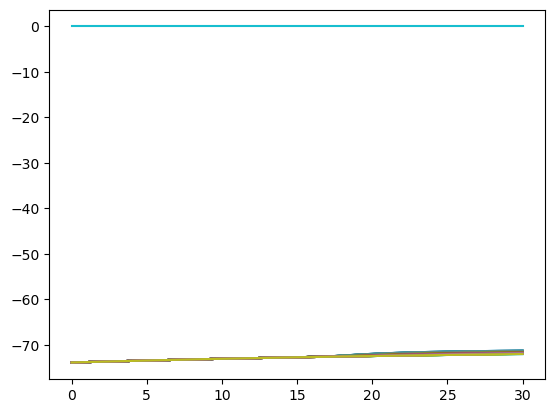

In [13]:
plt.plot(dpl[0].times, vmem.T)

In [15]:
vmem.shape

(100, 601)

In [6]:
# L2 PYR - L2 PYR
epsp_l2pyr_l2pyr, v_mem_l2pyr_l2pyr = get_psp(src_cell="L2_pyramidal", trgt_cell="L2_pyramidal", ampl=1, tsamp=len(dpl[0].times))

# L5ET - L5ET
epsp_l5pyr_l5pyr, v_mem_l5pyr_l5pyr = get_psp(src_cell="L5ET", trgt_cell="L5ET", ampl=3, tsamp=len(dpl[0].times))

# L2 PYR - L2 PYR
epsp_l2pyr_l5pyr, v_mem_l2pyr_l5pyr = get_psp(src_cell="L2_pyramidal", trgt_cell="L5ET", ampl=1, tsamp=len(dpl[0].times))

# L2 PYR - L2 PV
epsp_l2pyr_l2pv, v_mem_l2pyr_l2pv = get_psp(src_cell="L2_pyramidal", trgt_cell="L2_basket", ampl=1, tsamp=len(dpl[0].times))

# L2 PYR - L5 PV
epsp_l2pyr_l5pv, v_mem_l2pyr_l5pv = get_psp(src_cell="L2_pyramidal", trgt_cell="L5_basket", ampl=1, tsamp=len(dpl[0].times))

# L5 PYR - L5 PV
epsp_l5pyr_l5pv, v_mem_l5pyr_l5pv = get_psp(src_cell="L5ET", trgt_cell="L5_basket", ampl=3, tsamp=len(dpl[0].times))


# IPSPs
# L2 PV - L2 PYR
ipsp_l2pv_l2pyr, v_mem_l2pv_l2pyr = get_psp(src_cell="L2_basket", trgt_cell="L2_pyramidal", ampl=0.5, tsamp=len(dpl[0].times))

# L5 PV - L5 PYR
ipsp_l5pv_l5pyr, v_mem_l5pv_l5pyr = get_psp(src_cell="L5_basket", trgt_cell="L5ET", ampl=0.5, tsamp=len(dpl[0].times))

# L2 SOM - L5 PYR
ipsp_l2som_l5pyr, v_mem_l2som_l5pyr = get_psp(src_cell="L2_basket", trgt_cell="L5ET", ampl=0.5, tsamp=len(dpl[0].times))

# I - I
ipsp_I_I, v_mem_I_I = get_psp(src_cell="L5_basket", trgt_cell="L5_basket", ampl=0.5, tsamp=len(dpl[0].times))



Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Applying calcium model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Applying calcium model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Applying calcium model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Applying calcium model baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1:

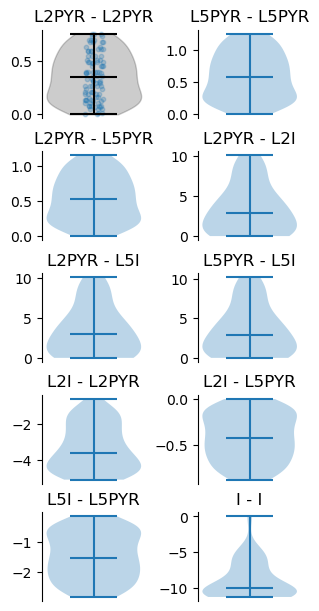

In [ ]:
fig, ax = plt.subplots(5,2, constrained_layout=True, figsize=(10, 6))

ax = ax.flatten()
v1 = ax[0].violinplot(epsp_l2pyr_l2pyr, showmedians=True)
v1['bodies'][0].set_alpha(0.2)
v1['bodies'][0].set_edgecolor('black')
v1['bodies'][0].set_facecolor('black')
ax[0].scatter(np.random.uniform(0.95,1.05,len(epsp_l2pyr_l2pyr)), epsp_l2pyr_l2pyr, s=10, alpha=0.25)

v1['cbars'].set_color('black')
v1['cmaxes'].set_color('black')
v1['cmins'].set_color('black')
v1['cmedians'].set_color('black')
ax[0].set_title('L2PYR - L2PYR')
ax[1].violinplot(epsp_l5pyr_l5pyr, showmedians=True)
ax[1].set_title('L5PYR - L5PYR')
ax[2].violinplot(epsp_l2pyr_l5pyr, showmedians=True)
ax[2].set_title('L2PYR - L5PYR')
ax[3].violinplot(epsp_l2pyr_l2pv, showmedians=True)
ax[3].set_title('L2PYR - L2I')
ax[4].violinplot(epsp_l2pyr_l2pv, showmedians=True)
ax[4].set_title('L2PYR - L5I')
ax[5].violinplot(epsp_l5pyr_l5pv, showmedians=True)
ax[5].set_title('L5PYR - L5I')
ax[6].violinplot(-ipsp_l2pv_l2pyr, showmedians=True)
ax[6].set_title('L2I - L2PYR')
ax[7].violinplot(-ipsp_l2som_l5pyr, showmedians=True)
ax[7].set_title('L2I - L5PYR')
ax[8].violinplot(-ipsp_l5pv_l5pyr, showmedians=True)
ax[8].set_title('L5I - L5PYR')
ax[9].violinplot(-ipsp_I_I, showmedians=True)
ax[9].set_title('I - I')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.spines['bottom'].set_visible(False)
    a.set_xticks([])

In [8]:
np.random.rand(0,1)

array([], shape=(0, 1), dtype=float64)

In [15]:
np.random.uniform(0.9,1.1,100)

array([1.08526441, 0.90073272, 0.95578974, 1.08647741, 0.9425308 ,
       0.9323187 , 1.04270463, 1.04788742, 1.06788006, 1.03243856,
       0.90285779, 0.97203086, 0.93151638, 0.90736948, 1.01304528,
       1.07829314, 0.904901  , 1.06651321, 0.97524058, 0.94889792,
       0.93433668, 1.04198548, 1.07394081, 1.09663536, 1.03141727,
       1.05721774, 0.95160856, 0.97961367, 0.97283862, 0.93256459,
       0.99346076, 0.96884747, 1.00639455, 0.94835277, 1.04309625,
       0.97711405, 1.09250798, 0.92171194, 1.01449328, 1.01044768,
       0.90997339, 1.08594856, 0.90968458, 0.99372166, 0.90907196,
       0.92486523, 0.90624474, 0.95432678, 0.9826958 , 0.92696511,
       1.05435073, 1.09401228, 0.95218817, 0.97519838, 1.01025055,
       1.04271903, 0.9697607 , 0.93522868, 0.96381629, 0.97521297,
       0.96062059, 0.97502483, 0.93281446, 1.0532728 , 0.91710226,
       1.09896558, 0.95145246, 0.96073372, 1.05198084, 0.97157179,
       1.01026592, 0.90858353, 1.05952177, 1.02753793, 1.04062